# Residency Project Day 2: Model Optimization, Real-World Impact, and Ethical Evaluation

**Team:** Damaries Ongole, Iman Parwaiz Sayeda, Sanjeev Koushik Sennam Setty

This notebook continues Day 1 (UCI Heart Disease, Cleveland). It tunes hyperparameters, chooses a decision threshold, evaluates the final model, and checks performance across subgroups. Run all cells in order (Runtime > Run all). The dataset is embedded, so no upload is needed.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import io
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_predict, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
sns.set_style('whitegrid')

## 1. Data and preprocessing (same as Day 1)

In [2]:
CSV_TEXT = '''age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
44,1,1,120,263,0,1,173,0,0,2,0,3,1
52,1,2,172,199,1,1,162,0,0.5,2,0,3,1
57,1,2,150,168,0,1,174,0,1.6,2,0,2,1
54,1,0,140,239,0,1,160,0,1.2,2,0,2,1
48,0,2,130,275,0,1,139,0,0.2,2,0,2,1
49,1,1,130,266,0,1,171,0,0.6,2,0,2,1
64,1,3,110,211,0,0,144,1,1.8,1,0,2,1
58,0,3,150,283,1,0,162,0,1,2,0,2,1
50,0,2,120,219,0,1,158,0,1.6,1,0,2,1
58,0,2,120,340,0,1,172,0,0,2,0,2,1
66,0,3,150,226,0,1,114,0,2.6,0,0,2,1
43,1,0,150,247,0,1,171,0,1.5,2,0,2,1
69,0,3,140,239,0,1,151,0,1.8,2,2,2,1
59,1,0,135,234,0,1,161,0,0.5,1,0,3,1
44,1,2,130,233,0,1,179,1,0.4,2,0,2,1
42,1,0,140,226,0,1,178,0,0,2,0,2,1
61,1,2,150,243,1,1,137,1,1,1,0,2,1
40,1,3,140,199,0,1,178,1,1.4,2,0,3,1
71,0,1,160,302,0,1,162,0,0.4,2,2,2,1
59,1,2,150,212,1,1,157,0,1.6,2,0,2,1
51,1,2,110,175,0,1,123,0,0.6,2,0,2,1
65,0,2,140,417,1,0,157,0,0.8,2,1,2,1
53,1,2,130,197,1,0,152,0,1.2,0,0,2,1
41,0,1,105,198,0,1,168,0,0,2,1,2,1
65,1,0,120,177,0,1,140,0,0.4,2,0,3,1
44,1,1,130,219,0,0,188,0,0,2,0,2,1
54,1,2,125,273,0,0,152,0,0.5,0,1,2,1
51,1,3,125,213,0,0,125,1,1.4,2,1,2,1
46,0,2,142,177,0,0,160,1,1.4,0,0,2,1
54,0,2,135,304,1,1,170,0,0,2,0,2,1
54,1,2,150,232,0,0,165,0,1.6,2,0,3,1
65,0,2,155,269,0,1,148,0,0.8,2,0,2,1
65,0,2,160,360,0,0,151,0,0.8,2,0,2,1
51,0,2,140,308,0,0,142,0,1.5,2,1,2,1
48,1,1,130,245,0,0,180,0,0.2,1,0,2,1
45,1,0,104,208,0,0,148,1,3,1,0,2,1
53,0,0,130,264,0,0,143,0,0.4,1,0,2,1
39,1,2,140,321,0,0,182,0,0,2,0,2,1
52,1,1,120,325,0,1,172,0,0.2,2,0,2,1
44,1,2,140,235,0,0,180,0,0,2,0,2,1
47,1,2,138,257,0,0,156,0,0,2,0,2,1
53,0,2,128,216,0,0,115,0,0,2,0,0,1
53,0,0,138,234,0,0,160,0,0,2,0,2,1
51,0,2,130,256,0,0,149,0,0.5,2,0,2,1
66,1,0,120,302,0,0,151,0,0.4,1,0,2,1
62,1,2,130,231,0,1,146,0,1.8,1,3,3,1
44,0,2,108,141,0,1,175,0,0.6,1,0,2,1
63,0,2,135,252,0,0,172,0,0,2,0,2,1
52,1,1,134,201,0,1,158,0,0.8,2,1,2,1
48,1,0,122,222,0,0,186,0,0,2,0,2,1
45,1,0,115,260,0,0,185,0,0,2,0,2,1
34,1,3,118,182,0,0,174,0,0,2,0,2,1
57,0,0,128,303,0,0,159,0,0,2,1,2,1
71,0,2,110,265,1,0,130,0,0,2,1,2,1
54,1,1,108,309,0,1,156,0,0,2,0,3,1
52,1,3,118,186,0,0,190,0,0,1,0,1,1
41,1,1,135,203,0,1,132,0,0,1,0,1,1
58,1,2,140,211,1,0,165,0,0,2,0,2,1
35,0,0,138,183,0,1,182,0,1.4,2,0,2,1
51,1,2,100,222,0,1,143,1,1.2,1,0,2,1
45,0,1,130,234,0,0,175,0,0.6,1,0,2,1
44,1,1,120,220,0,1,170,0,0,2,0,2,1
62,0,0,124,209,0,1,163,0,0,2,0,2,1
54,1,2,120,258,0,0,147,0,0.4,1,0,3,1
51,1,2,94,227,0,1,154,1,0,2,1,3,1
29,1,1,130,204,0,0,202,0,0,2,0,2,1
51,1,0,140,261,0,0,186,1,0,2,0,2,1
43,0,2,122,213,0,1,165,0,0.2,1,0,2,1
55,0,1,135,250,0,0,161,0,1.4,1,0,2,1
51,1,2,125,245,1,0,166,0,2.4,1,0,2,1
59,1,1,140,221,0,1,164,1,0,2,0,2,1
52,1,1,128,205,1,1,184,0,0,2,0,2,1
58,1,2,105,240,0,0,154,1,0.6,1,0,3,1
41,1,2,112,250,0,1,179,0,0,2,0,2,1
45,1,1,128,308,0,0,170,0,0,2,0,2,1
60,0,2,102,318,0,1,160,0,0,2,1,2,1
52,1,3,152,298,1,1,178,0,1.2,1,0,3,1
42,0,0,102,265,0,0,122,0,0.6,1,0,2,1
67,0,2,115,564,0,0,160,0,1.6,1,0,3,1
68,1,2,118,277,0,1,151,0,1,2,1,3,1
46,1,1,101,197,1,1,156,0,0,2,0,3,1
54,0,2,110,214,0,1,158,0,1.6,1,0,2,1
58,0,0,100,248,0,0,122,0,1,1,0,2,1
48,1,2,124,255,1,1,175,0,0,2,2,2,1
57,1,0,132,207,0,1,168,1,0,2,0,3,1
52,1,2,138,223,0,1,169,0,0,2,4,2,1
54,0,1,132,288,1,0,159,1,0,2,1,2,1
45,0,1,112,160,0,1,138,0,0,1,0,2,1
53,1,0,142,226,0,0,111,1,0,2,0,3,1
62,0,0,140,394,0,0,157,0,1.2,1,0,2,1
52,1,0,108,233,1,1,147,0,0.1,2,3,3,1
43,1,2,130,315,0,1,162,0,1.9,2,1,2,1
53,1,2,130,246,1,0,173,0,0,2,3,2,1
42,1,3,148,244,0,0,178,0,0.8,2,2,2,1
59,1,3,178,270,0,0,145,0,4.2,0,0,3,1
63,0,1,140,195,0,1,179,0,0,2,2,2,1
42,1,2,120,240,1,1,194,0,0.8,0,0,3,1
50,1,2,129,196,0,1,163,0,0,2,0,2,1
68,0,2,120,211,0,0,115,0,1.5,1,0,2,1
69,1,3,160,234,1,0,131,0,0.1,1,1,2,1
45,0,0,138,236,0,0,152,1,0.2,1,0,2,1
50,0,1,120,244,0,1,162,0,1.1,2,0,2,1
50,0,0,110,254,0,0,159,0,0,2,0,2,1
64,0,0,180,325,0,1,154,1,0,2,0,2,1
57,1,2,150,126,1,1,173,0,0.2,2,1,3,1
64,0,2,140,313,0,1,133,0,0.2,2,0,3,1
43,1,0,110,211,0,1,161,0,0,2,0,3,1
55,1,1,130,262,0,1,155,0,0,2,0,2,1
37,0,2,120,215,0,1,170,0,0,2,0,2,1
41,1,2,130,214,0,0,168,0,2,1,0,2,1
56,1,3,120,193,0,0,162,0,1.9,1,0,3,1
46,0,1,105,204,0,1,172,0,0,2,0,2,1
46,0,0,138,243,0,0,152,1,0,1,0,2,1
64,0,0,130,303,0,1,122,0,2,1,2,2,1
59,1,0,138,271,0,0,182,0,0,2,0,2,1
41,0,2,112,268,0,0,172,1,0,2,0,2,1
54,0,2,108,267,0,0,167,0,0,2,0,2,1
39,0,2,94,199,0,1,179,0,0,2,0,2,1
34,0,1,118,210,0,1,192,0,0.7,2,0,2,1
47,1,0,112,204,0,1,143,0,0.1,2,0,2,1
67,0,2,152,277,0,1,172,0,0,2,1,2,1
52,0,2,136,196,0,0,169,0,0.1,1,0,2,1
74,0,1,120,269,0,0,121,1,0.2,2,1,2,1
54,0,2,160,201,0,1,163,0,0,2,1,2,1
49,0,1,134,271,0,1,162,0,0,1,0,2,1
42,1,1,120,295,0,1,162,0,0,2,0,2,1
41,1,1,110,235,0,1,153,0,0,2,0,2,1
41,0,1,126,306,0,1,163,0,0,2,0,2,1
49,0,0,130,269,0,1,163,0,0,2,0,2,1
60,0,2,120,178,1,1,96,0,0,2,0,2,1
62,1,1,128,208,1,0,140,0,0,2,0,2,1
57,1,0,110,201,0,1,126,1,1.5,1,0,1,1
64,1,0,128,263,0,1,105,1,0.2,1,1,3,1
51,0,2,120,295,0,0,157,0,0.6,2,0,2,1
43,1,0,115,303,0,1,181,0,1.2,1,0,2,1
42,0,2,120,209,0,1,173,0,0,1,0,2,1
67,0,0,106,223,0,1,142,0,0.3,2,2,2,1
76,0,2,140,197,0,2,116,0,1.1,1,0,2,1
70,1,1,156,245,0,0,143,0,0,2,0,2,1
44,0,2,118,242,0,1,149,0,0.3,1,1,2,1
60,0,3,150,240,0,1,171,0,0.9,2,0,2,1
44,1,2,120,226,0,1,169,0,0,2,0,2,1
42,1,2,130,180,0,1,150,0,0,2,0,2,1
66,1,0,160,228,0,0,138,0,2.3,2,0,1,1
71,0,0,112,149,0,1,125,0,1.6,1,0,2,1
64,1,3,170,227,0,0,155,0,0.6,1,0,3,1
66,0,2,146,278,0,0,152,0,0,1,1,2,1
39,0,2,138,220,0,1,152,0,0,1,0,2,1
58,0,0,130,197,0,1,131,0,0.6,1,0,2,1
47,1,2,130,253,0,1,179,0,0,2,0,2,1
35,1,1,122,192,0,1,174,0,0,2,0,2,1
58,1,1,125,220,0,1,144,0,0.4,1,4,3,1
56,1,1,130,221,0,0,163,0,0,2,0,3,1
56,1,1,120,240,0,1,169,0,0,0,0,2,1
55,0,1,132,342,0,1,166,0,1.2,2,0,2,1
41,1,1,120,157,0,1,182,0,0,2,0,2,1
38,1,2,138,175,0,1,173,0,0,2,4,2,1
38,1,2,138,175,0,1,173,0,0,2,4,2,1
67,1,0,160,286,0,0,108,1,1.5,1,3,2,0
67,1,0,120,229,0,0,129,1,2.6,1,2,3,0
62,0,0,140,268,0,0,160,0,3.6,0,2,2,0
63,1,0,130,254,0,0,147,0,1.4,1,1,3,0
53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
56,1,2,130,256,1,0,142,1,0.6,1,1,1,0
48,1,1,110,229,0,1,168,0,1,0,0,3,0
58,1,1,120,284,0,0,160,0,1.8,1,0,2,0
58,1,2,132,224,0,0,173,0,3.2,2,2,3,0
60,1,0,130,206,0,0,132,1,2.4,1,2,3,0
40,1,0,110,167,0,0,114,1,2,1,0,3,0
60,1,0,117,230,1,1,160,1,1.4,2,2,3,0
64,1,2,140,335,0,1,158,0,0,2,0,2,0
43,1,0,120,177,0,0,120,1,2.5,1,0,3,0
57,1,0,150,276,0,0,112,1,0.6,1,1,1,0
55,1,0,132,353,0,1,132,1,1.2,1,1,3,0
65,0,0,150,225,0,0,114,0,1,1,3,3,0
61,0,0,130,330,0,0,169,0,0,2,0,2,0
58,1,2,112,230,0,0,165,0,2.5,1,1,3,0
50,1,0,150,243,0,0,128,0,2.6,1,0,3,0
44,1,0,112,290,0,0,153,0,0,2,1,2,0
60,1,0,130,253,0,1,144,1,1.4,2,1,3,0
54,1,0,124,266,0,0,109,1,2.2,1,1,3,0
50,1,2,140,233,0,1,163,0,0.6,1,1,3,0
41,1,0,110,172,0,0,158,0,0,2,0,3,0
51,0,0,130,305,0,1,142,1,1.2,1,0,3,0
58,1,0,128,216,0,0,131,1,2.2,1,3,3,0
54,1,0,120,188,0,1,113,0,1.4,1,1,3,0
60,1,0,145,282,0,0,142,1,2.8,1,2,3,0
60,1,2,140,185,0,0,155,0,3,1,0,2,0
59,1,0,170,326,0,0,140,1,3.4,0,0,3,0
46,1,2,150,231,0,1,147,0,3.6,1,0,2,0
67,1,0,125,254,1,1,163,0,0.2,1,2,3,0
62,1,0,120,267,0,1,99,1,1.8,1,2,3,0
65,1,0,110,248,0,0,158,0,0.6,2,2,1,0
44,1,0,110,197,0,0,177,0,0,2,1,2,0
60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
58,1,0,150,270,0,0,111,1,0.8,2,0,3,0
68,1,2,180,274,1,0,150,1,1.6,1,0,3,0
62,0,0,160,164,0,0,145,0,6.2,0,3,3,0
52,1,0,128,255,0,1,161,1,0,2,1,3,0
59,1,0,110,239,0,0,142,1,1.2,1,1,3,0
60,0,0,150,258,0,0,157,0,2.6,1,2,3,0
49,1,2,120,188,0,1,139,0,2,1,3,3,0
59,1,0,140,177,0,1,162,1,0,2,1,3,0
57,1,2,128,229,0,0,150,0,0.4,1,1,3,0
61,1,0,120,260,0,1,140,1,3.6,1,1,3,0
39,1,0,118,219,0,1,140,0,1.2,1,0,3,0
61,0,0,145,307,0,0,146,1,1,1,0,3,0
56,1,0,125,249,1,0,144,1,1.2,1,1,2,0
43,0,0,132,341,1,0,136,1,3,1,0,3,0
62,0,2,130,263,0,1,97,0,1.2,1,1,3,0
63,1,0,130,330,1,0,132,1,1.8,2,3,3,0
65,1,0,135,254,0,0,127,0,2.8,1,1,3,0
48,1,0,130,256,1,0,150,1,0,2,2,3,0
63,0,0,150,407,0,0,154,0,4,1,3,3,0
55,1,0,140,217,0,1,111,1,5.6,0,0,3,0
65,1,3,138,282,1,0,174,0,1.4,1,1,2,0
56,0,0,200,288,1,0,133,1,4,0,2,3,0
54,1,0,110,239,0,1,126,1,2.8,1,1,3,0
70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
62,1,1,120,281,0,0,103,0,1.4,1,1,3,0
35,1,0,120,198,0,1,130,1,1.6,1,0,3,0
59,1,3,170,288,0,0,159,0,0.2,1,0,3,0
64,1,2,125,309,0,1,131,1,1.8,1,0,3,0
47,1,2,108,243,0,1,152,0,0,2,0,2,0
57,1,0,165,289,1,0,124,0,1,1,3,3,0
55,1,0,160,289,0,0,145,1,0.8,1,1,3,0
64,1,0,120,246,0,0,96,1,2.2,0,1,2,0
70,1,0,130,322,0,0,109,0,2.4,1,3,2,0
51,1,0,140,299,0,1,173,1,1.6,2,0,3,0
58,1,0,125,300,0,0,171,0,0,2,2,3,0
60,1,0,140,293,0,0,170,0,1.2,1,2,3,0
77,1,0,125,304,0,0,162,1,0,2,3,2,0
35,1,0,126,282,0,0,156,1,0,2,0,3,0
70,1,2,160,269,0,1,112,1,2.9,1,1,3,0
59,0,0,174,249,0,1,143,1,0,1,0,2,0
64,1,0,145,212,0,0,132,0,2,1,2,1,0
57,1,0,152,274,0,1,88,1,1.2,1,1,3,0
56,1,0,132,184,0,0,105,1,2.1,1,1,1,0
48,1,0,124,274,0,0,166,0,0.5,1,0,3,0
56,0,0,134,409,0,0,150,1,1.9,1,2,3,0
66,1,1,160,246,0,1,120,1,0,1,3,1,0
54,1,1,192,283,0,0,195,0,0,2,1,3,0
69,1,2,140,254,0,0,146,0,2,1,3,3,0
51,1,0,140,298,0,1,122,1,4.2,1,3,3,0
43,1,0,132,247,1,0,143,1,0.1,1,4,3,0
62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
67,1,0,100,299,0,0,125,1,0.9,1,2,2,0
59,1,3,160,273,0,0,125,0,0,2,0,2,0
45,1,0,142,309,0,0,147,1,0,1,3,3,0
58,1,0,128,259,0,0,130,1,3,1,2,3,0
50,1,0,144,200,0,0,126,1,0.9,1,0,3,0
62,0,0,150,244,0,1,154,1,1.4,1,0,2,0
38,1,3,120,231,0,1,182,1,3.8,1,0,3,0
66,0,0,178,228,1,1,165,1,1,1,2,3,0
52,1,0,112,230,0,1,160,0,0,2,1,2,0
53,1,0,123,282,0,1,95,1,2,1,2,3,0
63,0,0,108,269,0,1,169,1,1.8,1,2,2,0
54,1,0,110,206,0,0,108,1,0,1,1,2,0
66,1,0,112,212,0,0,132,1,0.1,2,1,2,0
55,0,0,180,327,0,2,117,1,3.4,1,0,2,0
49,1,2,118,149,0,0,126,0,0.8,2,3,2,0
54,1,0,122,286,0,0,116,1,3.2,1,2,2,0
56,1,0,130,283,1,0,103,1,1.6,0,0,3,0
46,1,0,120,249,0,0,144,0,0.8,2,0,3,0
61,1,3,134,234,0,1,145,0,2.6,1,2,2,0
67,1,0,120,237,0,1,71,0,1,1,0,2,0
58,1,0,100,234,0,1,156,0,0.1,2,1,3,0
47,1,0,110,275,0,0,118,1,1,1,1,2,0
52,1,0,125,212,0,1,168,0,1,2,2,3,0
58,1,0,146,218,0,1,105,0,2,1,1,3,0
57,1,1,124,261,0,1,141,0,0.3,2,0,3,0
58,0,1,136,319,1,0,152,0,0,2,2,2,0
61,1,0,138,166,0,0,125,1,3.6,1,1,2,0
42,1,0,136,315,0,1,125,1,1.8,1,0,1,0
52,1,0,128,204,1,1,156,1,1,1,0,0,0
59,1,2,126,218,1,1,134,0,2.2,1,1,1,0
40,1,0,152,223,0,1,181,0,0,2,0,3,0
61,1,0,140,207,0,0,138,1,1.9,2,1,3,0
46,1,0,140,311,0,1,120,1,1.8,1,2,3,0
59,1,3,134,204,0,1,162,0,0.8,2,2,2,0
57,1,1,154,232,0,0,164,0,0,2,1,2,0
57,1,0,110,335,0,1,143,1,3,1,1,3,0
55,0,0,128,205,0,2,130,1,2,1,1,3,0
61,1,0,148,203,0,1,161,0,0,2,1,3,0
58,1,0,114,318,0,2,140,0,4.4,0,3,1,0
58,0,0,170,225,1,0,146,1,2.8,1,2,1,0
67,1,2,152,212,0,0,150,0,0.8,1,0,3,0
44,1,0,120,169,0,1,144,1,2.8,0,0,1,0
63,1,0,140,187,0,0,144,1,4,2,2,3,0
63,0,0,124,197,0,1,136,1,0,1,0,2,0
59,1,0,164,176,1,0,90,0,1,1,2,1,0
57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
57,0,1,130,236,0,0,174,0,0,1,1,2,0'''
df = pd.read_csv(io.StringIO(CSV_TEXT)).drop_duplicates().reset_index(drop=True)
X = df.drop(columns='target'); y = df.target
num=['age','trestbps','chol','thalach','oldpeak']; cat=['sex','cp','fbs','restecg','exang','slope','ca','thal']
pre=ColumnTransformer([('n',StandardScaler(),num),('c',OneHotEncoder(handle_unknown='ignore'),cat)])
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.25,stratify=y,random_state=42)
cv=StratifiedKFold(5,shuffle=True,random_state=42)
def metrics(y,p,pb): return dict(accuracy=accuracy_score(y,p),precision=precision_score(y,p),recall=recall_score(y,p),f1=f1_score(y,p),roc_auc=roc_auc_score(y,pb))
print(df.shape, 'train:',len(Xtr),'test:',len(Xte))

(302, 14) train: 226 test: 76


## 2. Baselines (from Day 1)

In [3]:
base={}; base_proba={}
for n,c in {'Baseline Logistic Regression':LogisticRegression(max_iter=1000),'Baseline Random Forest':RandomForestClassifier(n_estimators=300,random_state=42)}.items():
    p=Pipeline([('pre',pre),('clf',c)]).fit(Xtr,ytr)
    base_proba[n]=p.predict_proba(Xte)[:,1]; base[n]=metrics(yte,p.predict(Xte),base_proba[n])
pd.DataFrame(base).T.round(3)

,accuracy,precision,recall,f1,roc_auc
Baseline Logistic Regression,0.803,0.783,0.878,0.828,0.895
Baseline Random Forest,0.750,0.739,0.829,0.782,0.879


## 3. Hyperparameter tuning (5-fold stratified CV on the training set, scored by ROC-AUC)

In [4]:
lr=Pipeline([('pre',pre),('clf',LogisticRegression(max_iter=2000,solver='liblinear'))])
glr=GridSearchCV(lr,{'clf__C':[0.01,0.1,0.3,1,3,10],'clf__penalty':['l1','l2']},cv=cv,scoring='roc_auc').fit(Xtr,ytr)
rf=Pipeline([('pre',pre),('clf',RandomForestClassifier(random_state=42))])
grf=GridSearchCV(rf,{'clf__n_estimators':[100,300],'clf__max_depth':[3,5,10,None],'clf__min_samples_leaf':[1,3,5],'clf__min_samples_split':[2,5]},cv=cv,scoring='roc_auc').fit(Xtr,ytr)
print('Logistic Regression:',glr.best_params_,'CV AUC =',round(glr.best_score_,3))
print('Random Forest:',grf.best_params_,'CV AUC =',round(grf.best_score_,3))
best = grf if grf.best_score_>=glr.best_score_ else glr
print('Selected by cross-validation:', 'Random Forest' if best is grf else 'Logistic Regression')

Logistic Regression: {'clf__C': 0.3, 'clf__penalty': 'l2'} CV AUC = 0.912
Random Forest: {'clf__max_depth': 10, 'clf__min_samples_leaf': 3, 'clf__min_samples_split': 2, 'clf__n_estimators': 100} CV AUC = 0.918
Selected by cross-validation: Random Forest


## 4. Decision-threshold tuning (cross-validated predictions on the training set only)

In [5]:
pcv=cross_val_predict(best.best_estimator_,Xtr,ytr,cv=cv,method='predict_proba')[:,1]
for t in [0.5,0.45,0.4,0.35,0.3]:
    pr=(pcv>=t).astype(int)
    print(f'threshold {t:.2f}: CV recall = {recall_score(ytr,pr):.3f}, CV precision = {precision_score(ytr,pr):.3f}')
THRESH = 0.40  # chosen because a missed diagnosis costs more than a follow-up test

threshold 0.50: CV recall = 0.862, CV precision = 0.876
threshold 0.45: CV recall = 0.902, CV precision = 0.847
threshold 0.40: CV recall = 0.919, CV precision = 0.785
threshold 0.35: CV recall = 0.943, CV precision = 0.768
threshold 0.30: CV recall = 0.959, CV precision = 0.728


## 5. Final evaluation on the held-out test set

In [6]:
tuned_lr_p=glr.predict_proba(Xte)[:,1]; tuned_rf_p=grf.predict_proba(Xte)[:,1]
rows=dict(base)
rows['Tuned Logistic Regression']=metrics(yte,(tuned_lr_p>=0.5).astype(int),tuned_lr_p)
rows['Tuned Random Forest (0.50)']=metrics(yte,(tuned_rf_p>=0.5).astype(int),tuned_rf_p)
final_pred=(tuned_rf_p>=THRESH).astype(int)
rows['Final: Tuned Random Forest (0.40)']=metrics(yte,final_pred,tuned_rf_p)
display(pd.DataFrame(rows).T.round(3))
print('Final confusion matrix [[TN, FP], [FN, TP]]:',confusion_matrix(yte,final_pred).tolist())

,accuracy,precision,recall,f1,roc_auc
Baseline Logistic Regression,0.803,0.783,0.878,0.828,0.895
Baseline Random Forest,0.750,0.739,0.829,0.782,0.879
Tuned Logistic Regression,0.816,0.800,0.878,0.837,0.895
Tuned Random Forest (0.50),0.763,0.745,0.854,0.795,0.889
Final: Tuned Random Forest (0.40),0.750,0.712,0.902,0.796,0.889


Final confusion matrix [[TN, FP], [FN, TP]]: [[20, 15], [4, 37]]


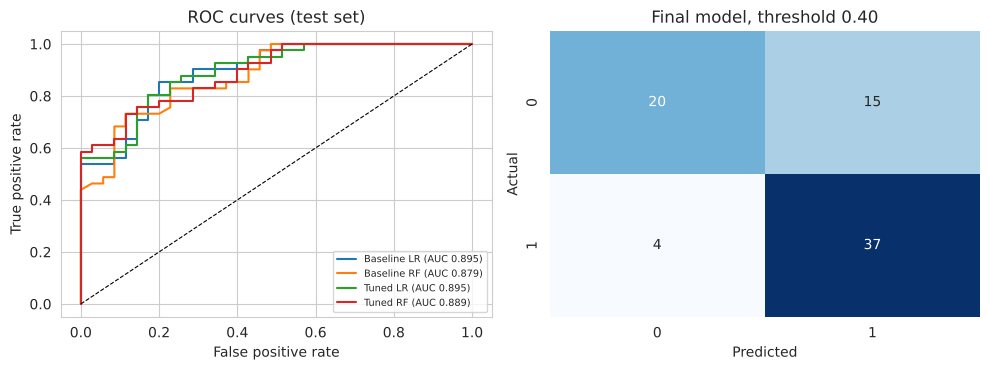

In [7]:
fig,ax=plt.subplots(1,2,figsize=(10,3.8))
for n,pb in [('Baseline LR',base_proba['Baseline Logistic Regression']),('Baseline RF',base_proba['Baseline Random Forest']),('Tuned LR',tuned_lr_p),('Tuned RF',tuned_rf_p)]:
    f,t_,_=roc_curve(yte,pb); ax[0].plot(f,t_,label=f'{n} (AUC {roc_auc_score(yte,pb):.3f})')
ax[0].plot([0,1],[0,1],'k--',lw=.8); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate'); ax[0].set_title('ROC curves (test set)'); ax[0].legend(fontsize=7,loc='lower right')
sns.heatmap(confusion_matrix(yte,final_pred),annot=True,fmt='d',cmap='Blues',cbar=False,ax=ax[1]); ax[1].set_title('Final model, threshold 0.40'); ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Actual')
plt.tight_layout(); plt.show()

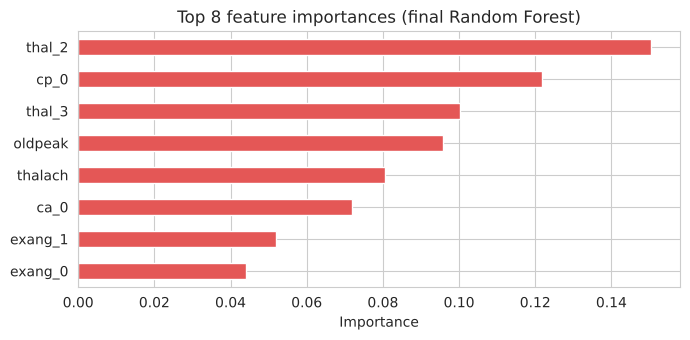

In [8]:
names=[n.split('__')[1] for n in grf.best_estimator_.named_steps['pre'].get_feature_names_out()]
imp=pd.Series(grf.best_estimator_.named_steps['clf'].feature_importances_,index=names).sort_values()
imp.tail(8).plot.barh(color='#E45756',figsize=(7,3.5)); plt.title('Top 8 feature importances (final Random Forest)'); plt.xlabel('Importance'); plt.tight_layout(); plt.show()

## 6. Ethical evaluation: performance by subgroup

Subgroups are small (26 to 50 test records), so these estimates are noisy and should be treated as a warning sign, not a conclusion.

In [9]:
t=Xte.copy(); t['y']=yte.values; t['p']=final_pred; t['age_band']=np.where(t.age<55,'under 55','55 and over')
rows=[]
for col in ['sex','age_band']:
    for k,gp in t.groupby(col):
        rows.append((f'{col} = {k}',len(gp),accuracy_score(gp.y,gp.p),recall_score(gp.y,gp.p),precision_score(gp.y,gp.p)))
sg=pd.DataFrame(rows,columns=['subgroup','n','accuracy','recall','precision']).round(3)
display(sg)
print('Positive rate by sex in the full file:'); print(df.groupby('sex').target.mean().round(3))

,subgroup,n,accuracy,recall,precision
0,sex = 0,26,0.885,1.000,0.875
1,sex = 1,50,0.680,0.800,0.571
2,age_band = 55 and over,38,0.632,0.800,0.522
3,age_band = under 55,38,0.868,0.962,0.862


Positive rate by sex in the full file:
sex
0    0.750
1    0.447
Name: target, dtype: float64


## Notes

- The final model was chosen using cross-validation on the training set, not the test set.
- This is an educational proof of concept, not a validated diagnostic tool.